# Analisis Pola Pelanggan dengan Unsupervised Learning
**Notebook praktikum — Python, Google Colab**

Notebook ini menggunakan dataset sintetis pelanggan yang dibuat langsung di dalam notebook. Tujuannya adalah mengeksplorasi pola data tanpa label, membandingkan hasil clustering K-Means, dan melihat ringkasan kelompok pelanggan.

> Topik ini mengambil inspirasi umum dari pembelajaran tanpa pengawasan (*unsupervised learning*), tetapi contoh, struktur analisis, dataset, dan kode disusun secara mandiri.

## 1. Tujuan
- Membuat dan memahami dataset pelanggan sederhana.
- Memeriksa distribusi serta hubungan antarvariabel.
- Menstandarkan fitur sebelum clustering.
- Memilih jumlah cluster menggunakan silhouette score.
- Menafsirkan karakteristik setiap kelompok.

**Catatan:** data yang digunakan adalah data simulasi, bukan data pelanggan nyata.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

SEED = 42
rng = np.random.default_rng(SEED)

print("Library berhasil dimuat.")

Library berhasil dimuat.


## 2. Membuat dataset simulasi\nKita membuat tiga pola pelanggan berdasarkan pendapatan tahunan dan skor aktivitas belanja. Angka sengaja dibuat sederhana agar hasilnya mudah dipahami.

In [2]:
n_per_group = 120

# Kelompok dengan aktivitas belanja hemat
hemat = pd.DataFrame({
    "usia": rng.normal(24, 5, n_per_group),
    "pendapatan_tahunan_juta": rng.normal(45, 12, n_per_group),
    "skor_belanja": rng.normal(30, 10, n_per_group)
})

# Kelompok pelanggan dengan pendapatan menengah dan aktivitas sedang
sedang = pd.DataFrame({
    "usia": rng.normal(38, 7, n_per_group),
    "pendapatan_tahunan_juta": rng.normal(85, 18, n_per_group),
    "skor_belanja": rng.normal(55, 12, n_per_group)
})

# Kelompok dengan pendapatan dan aktivitas belanja tinggi
aktif = pd.DataFrame({
    "usia": rng.normal(32, 6, n_per_group),
    "pendapatan_tahunan_juta": rng.normal(140, 25, n_per_group),
    "skor_belanja": rng.normal(82, 9, n_per_group)
})

df = pd.concat([hemat, sedang, aktif], ignore_index=True)
df["usia"] = df["usia"].clip(18, 70).round().astype(int)
df["pendapatan_tahunan_juta"] = df["pendapatan_tahunan_juta"].clip(15, 250).round(1)
df["skor_belanja"] = df["skor_belanja"].clip(1, 100).round(1)

# Acak urutan baris agar data tidak tersusun per kelompok
df = df.sample(frac=1, random_state=SEED).reset_index(drop=True)
df.head()

,usia,pendapatan_tahunan_juta,skor_belanja
0,30,97.9,67.6
1,21,70.5,39.3
2,21,147.2,85.1
3,43,136.3,85.7
4,23,63.9,33.0


## 3. Memeriksa kualitas data

In [3]:
print("Ukuran dataset:", df.shape)
display(df.describe().round(2))
print("\\nJumlah nilai kosong per kolom:")
display(df.isna().sum())
print("\\nJumlah baris duplikat:", df.duplicated().sum())

Ukuran dataset: (360, 3)


,usia,pendapatan_tahunan_juta,skor_belanja
count,360.00,360.00,360.00
mean,31.26,89.12,55.50
std,8.20,43.74,23.52
min,18.00,19.20,4.30
25%,25.00,49.28,34.65
50%,31.00,82.10,52.80
75%,37.00,124.65,77.75
max,56.00,219.50,100.00


\nJumlah nilai kosong per kolom:


,0
usia,0
pendapatan_tahunan_juta,0
skor_belanja,0


\nJumlah baris duplikat: 0


## 4. Eksplorasi visual

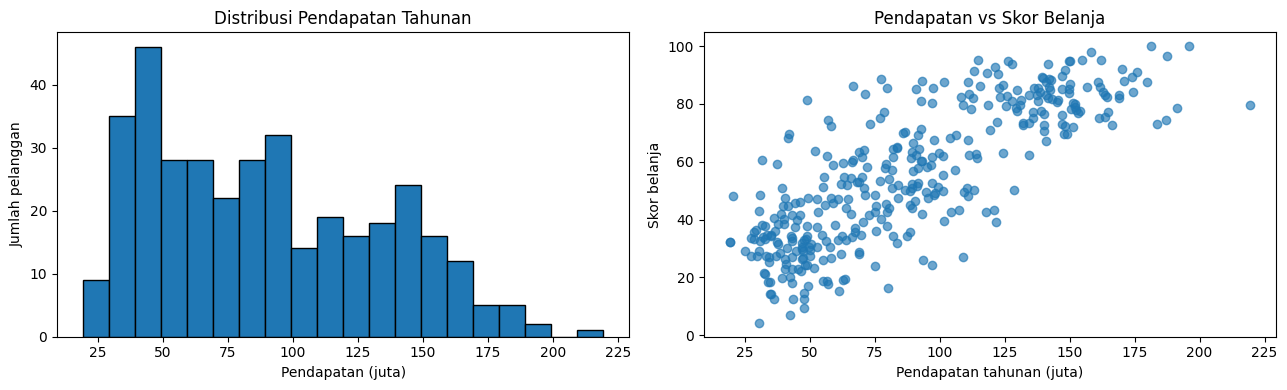

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].hist(df["pendapatan_tahunan_juta"], bins=20, edgecolor="black")
axes[0].set_title("Distribusi Pendapatan Tahunan")
axes[0].set_xlabel("Pendapatan (juta)")
axes[0].set_ylabel("Jumlah pelanggan")

axes[1].scatter(
    df["pendapatan_tahunan_juta"],
    df["skor_belanja"],
    alpha=0.65
)
axes[1].set_title("Pendapatan vs Skor Belanja")
axes[1].set_xlabel("Pendapatan tahunan (juta)")
axes[1].set_ylabel("Skor belanja")

plt.tight_layout()
plt.show()

**Pertanyaan pengamatan**
1. Apakah pendapatan pelanggan tersebar merata?
2. Apakah skor belanja cenderung meningkat bersama pendapatan?
3. Adakah pola kelompok yang terlihat pada scatter plot?

## 5. Menyiapkan fitur untuk clustering\nUsia, pendapatan, dan skor belanja memiliki skala berbeda. Standardisasi membantu mencegah fitur dengan angka besar mendominasi perhitungan jarak.

In [5]:
features = ["usia", "pendapatan_tahunan_juta", "skor_belanja"]
X = df[features].copy()

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Jumlah observasi:", X_scaled.shape[0])
print("Jumlah fitur:", X_scaled.shape[1])

Jumlah observasi: 360
Jumlah fitur: 3


## 6. Menentukan jumlah cluster\nSilhouette score membantu membandingkan pemisahan cluster. Nilainya berada pada rentang -1 hingga 1; skor lebih tinggi biasanya menunjukkan cluster yang lebih terpisah, tetapi tetap perlu ditafsirkan bersama konteks data.

,jumlah_cluster,silhouette_score
0,2,0.461
1,3,0.485
2,4,0.411
3,5,0.381
4,6,0.299
5,7,0.295


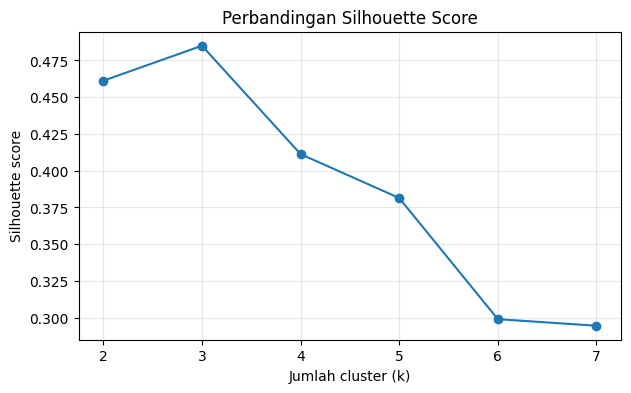

Jumlah cluster dengan skor tertinggi pada rentang uji: 3


In [6]:
scores = {}
for k in range(2, 8):
    model = KMeans(n_clusters=k, random_state=SEED, n_init=10)
    labels = model.fit_predict(X_scaled)
    scores[k] = silhouette_score(X_scaled, labels)

score_df = pd.DataFrame({
    "jumlah_cluster": list(scores.keys()),
    "silhouette_score": list(scores.values())
})
display(score_df.round(3))

plt.figure(figsize=(7, 4))
plt.plot(score_df["jumlah_cluster"], score_df["silhouette_score"], marker="o")
plt.xticks(score_df["jumlah_cluster"])
plt.xlabel("Jumlah cluster (k)")
plt.ylabel("Silhouette score")
plt.title("Perbandingan Silhouette Score")
plt.grid(alpha=0.3)
plt.show()

best_k = int(score_df.loc[score_df["silhouette_score"].idxmax(), "jumlah_cluster"])
print("Jumlah cluster dengan skor tertinggi pada rentang uji:", best_k)

## 7. Melatih model K-Means

In [7]:
kmeans = KMeans(n_clusters=best_k, random_state=SEED, n_init=10)
df["cluster"] = kmeans.fit_predict(X_scaled)

display(df.head(10))
print("Jumlah anggota setiap cluster:")
display(df["cluster"].value_counts().sort_index().rename("jumlah_pelanggan").to_frame())

,usia,pendapatan_tahunan_juta,skor_belanja,cluster
0,30,97.9,67.6,1
1,21,70.5,39.3,0
2,21,147.2,85.1,1
3,43,136.3,85.7,1
4,23,63.9,33.0,0
5,26,158.1,98.1,1
6,20,32.8,37.8,0
7,31,46.9,26.3,0
8,25,122.3,90.3,1
9,37,84.0,47.4,2


Jumlah anggota setiap cluster:


,jumlah_pelanggan
cluster,
0,135
1,119
2,106


## 8. Memvisualisasikan hasil dengan PCA\nPCA memproyeksikan fitur menjadi dua dimensi agar pola cluster lebih mudah divisualisasikan. Proyeksi ini menyederhanakan data, sehingga sebagian informasi dapat hilang.

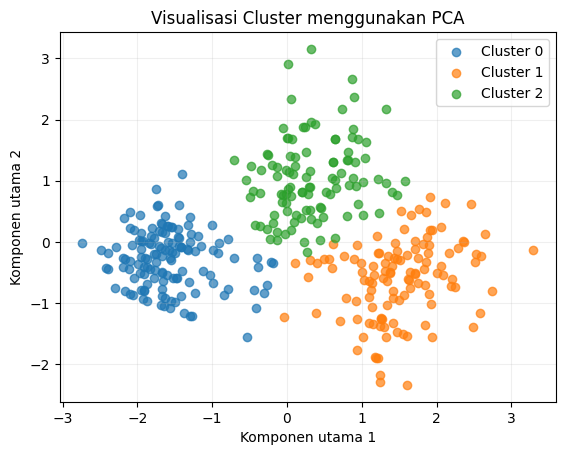

Proporsi variasi yang dijelaskan dua komponen: 93.29 %


In [8]:
pca = PCA(n_components=2, random_state=SEED)
coords = pca.fit_transform(X_scaled)

plot_df = pd.DataFrame({
    "Komponen 1": coords[:, 0],
    "Komponen 2": coords[:, 1],
    "Cluster": df["cluster"].astype(str)
})

for cluster_name in sorted(plot_df["Cluster"].unique(), key=int):
    subset = plot_df[plot_df["Cluster"] == cluster_name]
    plt.scatter(subset["Komponen 1"], subset["Komponen 2"],
                alpha=0.7, label=f"Cluster {cluster_name}")

plt.title("Visualisasi Cluster menggunakan PCA")
plt.xlabel("Komponen utama 1")
plt.ylabel("Komponen utama 2")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

print("Proporsi variasi yang dijelaskan dua komponen:",
      round(pca.explained_variance_ratio_.sum() * 100, 2), "%")

## 9. Menafsirkan karakteristik cluster

In [9]:
profile = df.groupby("cluster")[features].mean().round(2)
profile["jumlah_pelanggan"] = df.groupby("cluster").size()
display(profile.sort_values("pendapatan_tahunan_juta"))

print("Rata-rata keseluruhan:")
display(df[features].mean().round(2).to_frame("rata_rata"))

,usia,pendapatan_tahunan_juta,skor_belanja,jumlah_pelanggan
cluster,,,,
0,23.97,48.10,33.19,135
2,40.14,83.98,54.48,106
1,31.61,140.23,81.73,119


Rata-rata keseluruhan:


,rata_rata
usia,31.26
pendapatan_tahunan_juta,89.12
skor_belanja,55.50


### Cara membaca hasil
- Bandingkan rata-rata pendapatan dan skor belanja antarkelompok.
- Gunakan usia sebagai konteks tambahan, bukan satu-satunya dasar penamaan kelompok.
- Beri nama cluster setelah melihat hasil aktual; nomor cluster sendiri tidak memiliki makna urutan.
- Karena dataset disimulasikan, hasil ini hanya demonstrasi metode dan tidak bisa dijadikan dasar keputusan bisnis nyata.

## 10. Coba analisis sederhana

In [10]:
# Ubah nilai di bawah untuk memeriksa pelanggan dengan skor belanja tertentu
batas_skor = 70
pelanggan_aktif = df[df["skor_belanja"] >= batas_skor]

print(f"Pelanggan dengan skor belanja >= {batas_skor}: {len(pelanggan_aktif)}")
display(pelanggan_aktif.head(10))

Pelanggan dengan skor belanja >= 70: 122


,usia,pendapatan_tahunan_juta,skor_belanja,cluster
2,21,147.2,85.1,1
3,43,136.3,85.7,1
5,26,158.1,98.1,1
8,25,122.3,90.3,1
11,27,122.2,73.8,1
13,25,161.6,86.0,1
17,32,149.7,85.1,1
18,35,58.1,72.4,2
19,30,127.9,93.9,1
22,40,135.8,75.1,1


## 11. Kesimpulan
Dalam praktikum ini kita:
1. Membuat data simulasi dan memeriksa kualitasnya.
2. Mengeksplorasi distribusi dan hubungan antarfitur.
3. Menstandarkan data sebelum menghitung jarak.
4. Membandingkan beberapa jumlah cluster menggunakan silhouette score.
5. Memakai K-Means dan PCA untuk memeriksa serta menjelaskan pola.

**Pengembangan lanjutan:** ganti dataset simulasi dengan CSV milik sendiri, pilih fitur yang relevan, periksa nilai kosong dan pencilan, lalu bandingkan K-Means dengan hierarchical clustering.

## Referensi
- Topik umum: *Unsupervised Learning*, termasuk PCA dan clustering, dibahas dalam *Practical Statistics for Data Scientists*, edisi kedua.
- Ringkasan daftar isi penerbit: https://www.oreilly.com/library/view/practical-statistics-for/9781492072935/ch07.html
- Dokumentasi scikit-learn K-Means: https://scikit-learn.org/stable/modules/clustering.html#k-means
- Dokumentasi scikit-learn PCA: https://scikit-learn.org/stable/modules/decomposition.html#pca

Notebook ini adalah praktikum mandiri dengan data sintetis; bukan salinan notebook referensi.